# 2. Ricerca numerica dei parametri ottimali

Notebook a corredo della sezione 6 della tesina.

Finora i parametri del circuito sono stati assegnati e se ne sono osservate le conseguenze.
Qui si percorre la strada inversa: fissati un ingresso e un'uscita, si cercano i valori delle
fasi che rendono massima la probabilita' di quella transizione.

Il caso trattato e' la rete universale a quattro modi con ingresso $|1,1,1,0\rangle$ e uscita
$|0,0,0,3\rangle$, ossia i tre fotoni raccolti tutti nell'ultimo modo.

In [1]:
import numpy as np
import perceval as pcvl
from perceval.components import PS, BS
from scipy.optimize import minimize

print("Perceval", pcvl.__version__)

Perceval 1.3.1


## 2.1 La rete

`GenericInterferometer` costruisce la rete a strati alternati a partire da un blocco
elementare, qui una fase seguita da un beam splitter parametrico. Per $m = 4$ i blocchi sono
sei e i parametri liberi dodici.

12 parametri liberi


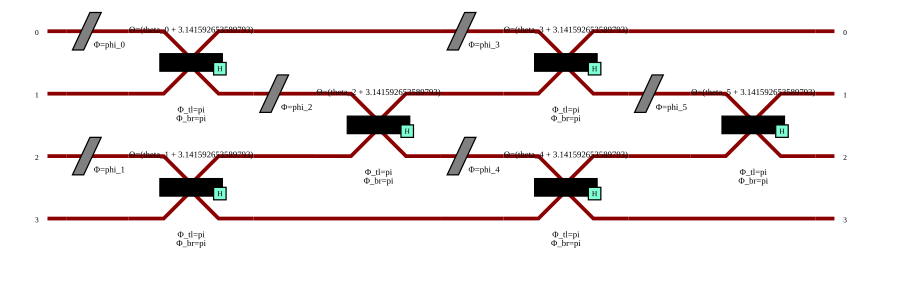

In [2]:
m = 4

circuito = pcvl.components.GenericInterferometer(
    m,
    fun_gen=lambda idx: (pcvl.Circuit(2, name="mzi")
                         .add(0, PS(pcvl.P(f"phi_{idx}")))
                         .add(0, BS.H(theta=pcvl.P(f"theta_{idx}") + np.pi,
                                      phi_tl=np.pi, phi_br=np.pi))),
    shape=pcvl.InterferometerShape.RECTANGLE)

parametri = circuito.get_parameters()
print(len(parametri), "parametri liberi")

pcvl.pdisplay(circuito)

## 2.2 La funzione da ottimizzare

L'ottimizzatore riceve un vettore di dodici numeri, li assegna ai parametri del circuito,
costruisce il simulatore e restituisce la probabilita' della transizione cercata, **cambiata
di segno**: `scipy.optimize.minimize` cerca infatti un minimo, e minimizzare $-p$ equivale a
massimizzare $p$.

In [3]:
ingresso = pcvl.BasicState([1, 1, 1, 0])
uscita   = pcvl.BasicState([0, 0, 0, 3])

def meno_probabilita(x):
    for valore, p in zip(x, circuito.get_parameters()):
        p.set_value(float(valore))
    simulatore = pcvl.SimulatorFactory().build(pcvl.Processor("SLOS", circuito))
    return -simulatore.probability(ingresso, uscita)

rng = np.random.default_rng(0)
x0 = rng.uniform(0, 2*np.pi, len(parametri))
print("probabilita' in un punto a caso:", -meno_probabilita(x0))

probabilita' in un punto a caso: 0.05420589720441208


## 2.3 L'ottimizzazione

La funzione non e' convessa e presenta minimi locali, sicche' una sola partenza non basta a
garantire che il massimo trovato sia quello globale. Si ripete percio' la ricerca da piu'
punti iniziali casuali e si tiene il risultato migliore.

In [4]:
risultati = []
for seme in range(8):
    rng = np.random.default_rng(seme)
    x0 = rng.uniform(0, 2*np.pi, len(parametri))
    res = minimize(meno_probabilita, x0)
    risultati.append(-res.fun)
    print(f"  partenza {seme}: p = {-res.fun:.6f}   ({res.nit} iterazioni)")

migliore = max(risultati)
print(f"\nmigliore su {len(risultati)} partenze: {migliore:.9f}")

  partenza 0: p = 0.222222   (16 iterazioni)


  partenza 1: p = 0.222222   (12 iterazioni)


  partenza 2: p = 0.222222   (14 iterazioni)


  partenza 3: p = 0.222222   (13 iterazioni)
  partenza 4: p = 0.000000   (0 iterazioni)


  partenza 5: p = 0.222222   (13 iterazioni)


  partenza 6: p = 0.222222   (14 iterazioni)


  partenza 7: p = 0.222222   (13 iterazioni)

migliore su 8 partenze: 0.222222222


## 2.4 Confronto con il massimo teorico

Il valore trovato va confrontato con la previsione analitica. Se i tre fotoni si
distribuissero in modo indipendente e uniforme sui quattro modi, la probabilita' di trovarli
tutti e tre in un modo assegnato sarebbe $(1/4)^3$. Il massimo si ottiene concentrando
l'ampiezza su tre modi soltanto, il che porta $1/4$ a $1/3$, e la statistica bosonica
aggiunge il fattore $3!$ proprio delle configurazioni affollate:

$$p_{\max} = 3!\left(\frac{1}{3}\right)^3 = \frac{6}{27} = \frac{2}{9} \simeq 0.2222 .$$

In [5]:
from math import factorial

teorico = factorial(3) * (1/3)**3
print(f"massimo numerico: {migliore:.9f}")
print(f"massimo teorico : {teorico:.9f}")
print(f"scarto          : {abs(migliore - teorico):.2e}")

massimo numerico: 0.222222222
massimo teorico : 0.222222222
scarto          : 2.56e-13
